# Daily Challenge: Binary Text Classification with the IMDB Dataset

In this daily challenge, I build, train, and evaluate a binary sentiment classification model on the IMDB dataset using Keras.

## Objectives
**What I learn**
- How to load and explore text sentiment sequences with `keras.datasets.imdb`
- How to vectorize variable-length integer sequences into multi-hot binary bag-of-words tensors
- How to partition data into training, validation, and test sets using the classic Chollet split
- How to construct and compile a binary classification MLP with Dense and ReLU layers
- How to train with RMSprop and binary cross-entropy loss while monitoring validation curves
- How to detect overfitting and identify the optimal stopping epoch
- How to retrain on the complete training set and evaluate on held-out test data
- How to export reproducible run metrics to JSON

## How I run this notebook
I open it in [Google Colab](https://colab.research.google.com) (**File → Upload notebook**) and run all cells from top to bottom (**Runtime → Run all**).
I can train this model on CPU. Runtime depends on the machine.
I load the IMDB dataset with `keras.datasets.imdb`. Keras downloads it on first use if it is missing from the cache.
Random seeds are fixed in the setup cell (Python, NumPy and TensorFlow, all set to 42), and the model is re-seeded before it is built, and I enable deterministic TensorFlow operations. The results I discuss below refer to the saved run.

## 1. Load and preprocess the IMDB dataset

The IMDB dataset contains 50,000 highly polarized movie reviews (25,000 for training and 25,000 for testing), evenly balanced between positive (label 1) and negative (label 0) sentiments.
I restrict the vocabulary to the top 10,000 most frequently occurring words (`num_words = 10_000`) to discard rare words and maintain manageable tensor dimensions.

**What this cell does:** fixes random seeds to 42, loads the IMDB dataset with the top 10,000 words, and displays raw sequence lengths and sample tokens.

In [1]:
import json
import os
import random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Fix seeds for reproducibility
random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)  # also seeds TensorFlow
tf.config.experimental.enable_op_determinism()  # repeatable CPU operations

num_words = 10_000
(train_data, train_labels), (test_data, test_labels) = keras.datasets.imdb.load_data(num_words=num_words)

print(f"Loaded {len(train_data)} training reviews and {len(test_data)} test reviews.")
print("Sample review (word index sequence):", train_data[0][:15], "...")
print(f"Sample review length: {len(train_data[0])} words")
print(f"Sample review sentiment label: {train_labels[0]} (1 = positive, 0 = negative)")

I0000 00:00:1795355084.725260  197046 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795355084.799162  197046 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795355085.999672  197046 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Loaded 25000 training reviews and 25000 test reviews.
Sample review (word index sequence): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4] ...
Sample review length: 218 words
Sample review sentiment label: 1 (1 = positive, 0 = negative)


The reviews are represented as variable-length lists of integers pointing to word dictionary indices. My Dense network expects a fixed number of input features per review.

To convert the sequences into tensors, I encode each review into a binary 10,000-dimensional vector (multi-hot bag-of-words representation). I set index `i` to 1 if token `i` appears anywhere in the sequence. The sequence also includes special tokens such as the start marker and the out-of-vocabulary marker.

Below is the exact `vectorize_sequences` function from the course brief.

**What this cell does:** defines the exact `vectorize_sequences` helper function from the brief, vectorizes training and test reviews into binary matrices, and casts labels to float32 NumPy arrays.

In [2]:
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1
    return results

# Vectorize features
x_train_full = vectorize_sequences(train_data, dimension=num_words)
x_test = vectorize_sequences(test_data, dimension=num_words)

# Convert labels to float32 numpy arrays
y_train_full = np.asarray(train_labels).astype("float32")
y_test = np.asarray(test_labels).astype("float32")

print("x_train_full shape:", x_train_full.shape, "| dtype:", x_train_full.dtype)
print("x_test shape:      ", x_test.shape, "| dtype:", x_test.dtype)
print("y_train_full shape:", y_train_full.shape, "| dtype:", y_train_full.dtype)
print("y_test shape:      ", y_test.shape, "| dtype:", y_test.dtype)

x_train_full shape: (25000, 10000) | dtype: float64
x_test shape:       (25000, 10000) | dtype: float64
y_train_full shape: (25000,) | dtype: float32
y_test shape:       (25000,) | dtype: float32


Now I create a validation split from the 25,000 training reviews using the classic Chollet split:
- The first 10,000 reviews are set aside for validation (`x_val`, `y_val`).
- The remaining 15,000 reviews form the partial training set (`x_train_part`, `y_train_part`).
- The test set retains all 25,000 original test reviews.

**What this cell does:** splits the 25,000 training samples into a 10,000-sample validation set and a 15,000-sample partial training set.

In [3]:
x_val = x_train_full[:10000]
x_train_part = x_train_full[10000:]

y_val = y_train_full[:10000]
y_train_part = y_train_full[10000:]

print(f"Partial training set: {x_train_part.shape}, labels: {y_train_part.shape}")
print(f"Validation set:       {x_val.shape}, labels: {y_val.shape}")
print(f"Test set:             {x_test.shape}, labels: {y_test.shape}")

Partial training set: (15000, 10000), labels: (15000,)
Validation set:       (10000, 10000), labels: (10000,)
Test set:             (25000, 10000), labels: (25000,)


## 2. Build the model architecture

I construct a `keras.Sequential` feedforward neural network comprising two hidden `Dense` layers followed by a single output unit.

Standard architecture choice: each of the two hidden layers contains 16 units with Rectified Linear Unit (`relu`) activation functions. Sixteen units is a common starting size. It is small enough to keep the model simple, but the curves in Section 4 show that it still overfits after a few epochs.
The input shape is `(10000,)`, matching my input vector size.
The output layer is a single `Dense` unit with `sigmoid` activation, which maps the output to a score between 0 and 1 that I interpret as an estimated probability of positive sentiment.

I compile the model with the `RMSprop` optimizer, `binary_crossentropy` loss function, and `accuracy` metric. Binary cross-entropy is the standard loss for a sigmoid output that predicts the probability of one of two classes.

**What this cell does:** defines, compiles, and displays the summary of the binary classification model.

In [4]:
tf.keras.utils.set_random_seed(42)  # same starting weights every run
model = keras.Sequential([
    layers.Input(shape=(10000,)),
    layers.Dense(16, activation="relu", name="dense_1"),
    layers.Dense(16, activation="relu", name="dense_2"),
    layers.Dense(1, activation="sigmoid", name="output")
], name="imdb_classifier")

model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "imdb_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 16)             │       160,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,305 (626.19 KB)

 Trainable params: 160,305 (626.19 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Train the model with validation monitoring

I train the network for 20 epochs using mini-batches of 512 samples on the partial training set `(x_train_part, y_train_part)` while validating against `(x_val, y_val)` at each epoch. The training history is retained for curve evaluation.

**What this cell does:** trains the model for 20 epochs on the partial training set with validation monitoring.

In [5]:
history = model.fit(
    x_train_part,
    y_train_part,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val),
    verbose=2
)

Epoch 1/20


E0000 00:00:1795355099.705683  197046 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


30/30 - 3s - 116ms/step - accuracy: 0.7762 - loss: 0.5288 - val_accuracy: 0.8646 - val_loss: 0.3964


Epoch 2/20


30/30 - 0s - 12ms/step - accuracy: 0.8901 - loss: 0.3252 - val_accuracy: 0.8843 - val_loss: 0.3092


Epoch 3/20


... (31 outputs left out)

Epoch 19/20


30/30 - 0s - 11ms/step - accuracy: 0.9977 - loss: 0.0198 - val_accuracy: 0.8706 - val_loss: 0.5317


Epoch 20/20


30/30 - 0s - 11ms/step - accuracy: 0.9971 - loss: 0.0197 - val_accuracy: 0.8699 - val_loss: 0.5536


## 4. Evaluate training curves and determine optimal epoch

I plot training and validation loss and accuracy across the 20 epochs to examine the learning dynamics and pinpoint the onset of overfitting.

**What this cell does:** plots training and validation loss and accuracy across all 20 epochs.

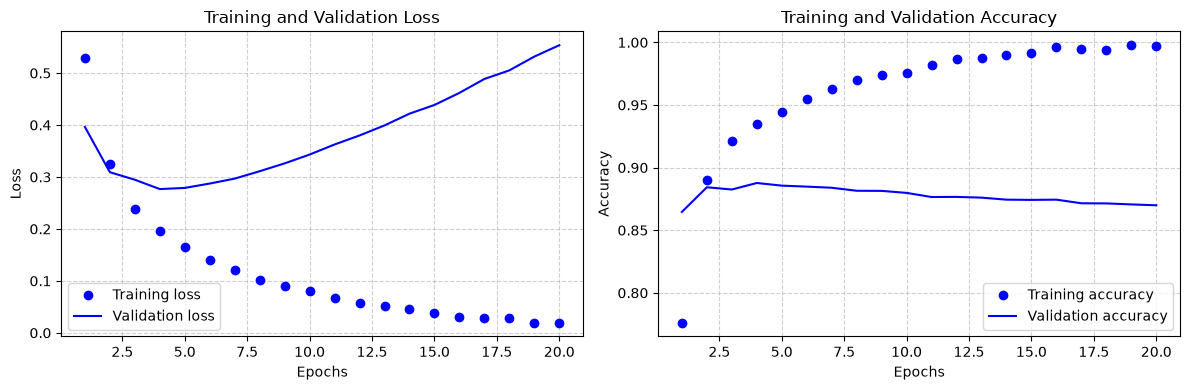

In [6]:
history_dict = history.history
epochs = range(1, len(history_dict["loss"]) + 1)

plt.figure(figsize=(12, 4))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, history_dict["loss"], "bo", label="Training loss")
plt.plot(epochs, history_dict["val_loss"], "b", label="Validation loss")
plt.title("Training and Validation Loss", fontsize=12)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, history_dict["accuracy"], "bo", label="Training accuracy")
plt.plot(epochs, history_dict["val_accuracy"], "b", label="Validation accuracy")
plt.title("Training and Validation Accuracy", fontsize=12)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

**Overfitting detection and analysis for the saved run:**
- The training loss falls every epoch, from 0.5288 to 0.0197, and training accuracy rises overall from 0.7762 to 0.9971, with a few dips.
- The validation loss behaves differently. It reaches its lowest value, 0.2767, at epoch 4, then climbs to 0.5536 by epoch 20.
- Validation accuracy peaks at 0.8877 at epoch 4 and then drifts down to 0.8699 by epoch 20.
- I take this divergence as evidence of overfitting. After epoch 4, the model keeps improving its fit on the training data while its validation loss rises.

**Optimal epoch selection and retraining:**
I use the 1-based epoch with the lowest validation loss to choose how long to train the fresh model. In this run that is epoch 4, and the code prints it.
I rebuild a fresh model from scratch and train it on the FULL original 25,000 training reviews (`x_train_full`, `y_train_full`) for exactly that many epochs, with no validation split needed for this second fit.
Finally, I evaluate this final model on the 25,000 test reviews.

**What this cell does:** identifies the optimal epoch, retrains a fresh model on the full 25,000 training reviews for that exact duration, and evaluates final test loss and accuracy.

In [7]:
# Find 1-based index of minimum validation loss
val_loss_values = history_dict["val_loss"]
optimal_epoch = int(np.argmin(val_loss_values) + 1)
val_loss_at_best = float(val_loss_values[optimal_epoch - 1])
val_acc_at_best = float(history_dict["val_accuracy"][optimal_epoch - 1])

print(f"Optimal epoch (minimum validation loss): {optimal_epoch}")
print(f"Validation loss at optimal epoch:     {val_loss_at_best:.4f}")
print(f"Validation accuracy at optimal epoch: {val_acc_at_best:.4f}")

# Rebuild fresh model from scratch
tf.keras.utils.set_random_seed(42)
np.random.seed(42)

final_model = keras.Sequential([
    layers.Input(shape=(10000,)),
    layers.Dense(16, activation="relu", name="dense_1"),
    layers.Dense(16, activation="relu", name="dense_2"),
    layers.Dense(1, activation="sigmoid", name="output")
], name="final_imdb_model")

final_model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Retrain on all 25,000 training samples
final_model.fit(
    x_train_full,
    y_train_full,
    epochs=optimal_epoch,
    batch_size=512,
    verbose=2
)

# Evaluate on the 25,000 test reviews
final_test_loss, final_test_acc = final_model.evaluate(x_test, y_test, verbose=0)
print(f"\nFinal test loss:     {final_test_loss:.4f}")
print(f"Final test accuracy: {final_test_acc:.4f}")

Optimal epoch (minimum validation loss): 4
Validation loss at optimal epoch:     0.2767
Validation accuracy at optimal epoch: 0.8877


Epoch 1/4


E0000 00:00:1795355113.089663  197046 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


49/49 - 1s - 21ms/step - accuracy: 0.8108 - loss: 0.4685


Epoch 2/4


49/49 - 0s - 6ms/step - accuracy: 0.9020 - loss: 0.2769


... (2 outputs left out)

Epoch 4/4


49/49 - 0s - 5ms/step - accuracy: 0.9352 - loss: 0.1831


E0000 00:00:1795355120.136560  197046 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}



Final test loss:     0.2899
Final test accuracy: 0.8836


## 5. Analyze and conclusion

**Comparison of training vs. validation dynamics in the saved run:**
- On the partial training set (15,000 reviews), training loss fell to 0.0197 and training accuracy reached 0.9971. Validation loss reached its minimum of 0.2767 at epoch 4 and rose to 0.5536 at epoch 20.
- Training past the best epoch made validation loss rise by about 0.28, even though training accuracy was close to perfect.

**Final test performance:**
- By retraining a fresh network on all 25,000 reviews for the same number of epochs as the best validation epoch (4 in this run), I used the full training set with the epoch count chosen in the first fit. The larger training split gives me more updates per epoch, so this is an estimate of how long to train.
- On the held-out 25,000 test reviews, the retrained model achieved a final test loss of 0.2899 and a final test accuracy of 0.8836.

**Conclusion:**
I used a small network with two hidden layers and multi-hot inputs to classify sentiment. The validation loss gave me a stopping point before I retrained on the full training split and measured performance on the held-out test set.

**What this cell does:** writes optimal epoch, validation metrics, and final test evaluation metrics to `artifacts/metrics.json`.

In [8]:
artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

metrics_data = {
    "dataset": "IMDB (keras.datasets.imdb)",
    "num_words": num_words,
    "raw_splits": {
        "total_train_samples": len(train_data),
        "partial_train_samples": len(x_train_part),
        "validation_samples": len(x_val),
        "test_samples": len(test_data)
    },
    "initial_20_epoch_run": {
        "total_epochs": 20,
        "optimal_epoch": optimal_epoch,
        "min_val_loss": float(val_loss_at_best),
        "val_acc_at_optimal_epoch": float(val_acc_at_best),
        "final_epoch_train_loss": float(history_dict["loss"][-1]),
        "final_epoch_train_acc": float(history_dict["accuracy"][-1]),
        "final_epoch_val_loss": float(history_dict["val_loss"][-1]),
        "final_epoch_val_acc": float(history_dict["val_accuracy"][-1])
    },
    "retrained_full_model": {
        "epochs_trained": optimal_epoch,
        "training_samples_used": len(x_train_full),
        "test_loss": float(final_test_loss),
        "test_accuracy": float(final_test_acc)
    }
}

metrics_file = artifacts_dir / "metrics.json"
with open(metrics_file, "w", encoding="utf-8") as f:
    json.dump(metrics_data, f, indent=4)

print(f"Metrics written successfully to {metrics_file}")

Metrics written successfully to artifacts/metrics.json
